In [ ]:
!pip install -q tensorflow tensorflow-datasets matplotlib scikit-learn seaborn

In [ ]:
import tensorflow as tf
import tensorflow_datasets as tfds
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import json
import os

from sklearn.metrics import classification_report, confusion_matrix

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.20.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
IMG_SIZE, BATCH_SIZE, SEED = 240, 16, 42
MODEL_NAME = "EfficientNetB1"

NUM_CLASSES = 101

print("Model:", MODEL_NAME)
print("Image size:", IMG_SIZE)
print("Batch size:", BATCH_SIZE)
print("Număr clase:", NUM_CLASSES)

Model: EfficientNetB1
Image size: 240
Batch size: 16
Număr clase: 101


In [ ]:
(ds_train, ds_test), ds_info = tfds.load(
    "food101",
    split=["train", "validation"],
    as_supervised=True,
    with_info=True
)

class_names = ds_info.features["label"].names
NUM_CLASSES = len(class_names)

print("Număr clase:", NUM_CLASSES)
print("Train images:", 750 * NUM_CLASSES)
print("Test images:", 250 * NUM_CLASSES)
print("Primele 10 clase:", class_names[:10])

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/2 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/food101/incomplete.L6OOTS_2.0.0/food101-train.tfrecord*...:   0%|         …

Generating validation examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/food101/incomplete.L6OOTS_2.0.0/food101-validation.tfrecord*...:   0%|    …

Dataset food101 downloaded and prepared to /root/tensorflow_datasets/food101/2.0.0. Subsequent calls will reuse this data.
Număr clase: 101
Train images: 75750
Test images: 25250
Primele 10 clase: ['apple_pie', 'baby_back_ribs', 'baklava', 'beef_carpaccio', 'beef_tartare', 'beet_salad', 'beignets', 'bibimbap', 'bread_pudding', 'breakfast_burrito']


In [ ]:
def preprocess(image, label):
    image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE))
    image = tf.cast(image, tf.float32)
    return image, label

train_ds = (
    ds_train
    .map(preprocess, num_parallel_calls=tf.data.AUTOTUNE)
    .shuffle(5000, seed=SEED)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

test_ds = (
    ds_test
    .map(preprocess, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

print("Dataset pregătit pentru EfficientNetB1.")

Dataset pregătit pentru EfficientNetB1.


In [ ]:
model = tf.keras.models.load_model(
    "/content/drive/MyDrive/nutritrack_models/best_food101_efficientnetb1.keras"
)

In [ ]:
from tensorflow.keras import layers, models

data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.1),
])

base_model = tf.keras.applications.EfficientNetB1(
    input_shape=(IMG_SIZE, IMG_SIZE, 3),
    include_top=False,
    weights="imagenet"
)

base_model.trainable = False

inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
x = data_augmentation(inputs)
x = tf.keras.applications.efficientnet.preprocess_input(x)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.4)(x)
outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)

model = models.Model(inputs, outputs)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.SparseTopKCategoricalAccuracy(k=3, name="top_3_accuracy"),
        tf.keras.metrics.SparseTopKCategoricalAccuracy(k=5, name="top_5_accuracy")
    ]
)

model.summary()

27018416/27018416 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 240, 240, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 240, 240, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb1 (Functional)     │ (None, 8, 8, 1280)     │     6,575,239 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 101)            │       129,381 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,704,620 (25.58 MB)

 Trainable params: 129,381 (505.39 KB)

 Non-trainable params: 6,575,239 (25.08 MB)

In [ ]:
callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        "/content/drive/MyDrive/nutritrack_models/best_food101_efficientnetb1.keras",
        monitor="val_accuracy",
        save_best_only=True,
        mode="max"
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_accuracy",
        patience=4,
        restore_best_weights=True
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.3,
        patience=2,
        min_lr=1e-7
    )
]

In [ ]:
history_1 = model.fit(
    train_ds,
    validation_data=test_ds,
    epochs=6,
    callbacks=callbacks
)

Epoch 1/6
4735/4735 ━━━━━━━━━━━━━━━━━━━━ 165s 31ms/step - accuracy: 0.4712 - loss: 2.1495 - top_3_accuracy: 0.6601 - top_5_accuracy: 0.7387 - val_accuracy: 0.6655 - val_loss: 1.2332 - val_top_3_accuracy: 0.8352 - val_top_5_accuracy: 0.8913 - learning_rate: 0.0010
Epoch 2/6
4735/4735 ━━━━━━━━━━━━━━━━━━━━ 146s 30ms/step - accuracy: 0.5482 - loss: 1.7816 - top_3_accuracy: 0.7327 - top_5_accuracy: 0.8051 - val_accuracy: 0.6866 - val_loss: 1.1472 - val_top_3_accuracy: 0.8507 - val_top_5_accuracy: 0.9036 - learning_rate: 0.0010
Epoch 3/6
4735/4735 ━━━━━━━━━━━━━━━━━━━━ 146s 30ms/step - accuracy: 0.5595 - loss: 1.7421 - top_3_accuracy: 0.7422 - top_5_accuracy: 0.8137 - val_accuracy: 0.6893 - val_loss: 1.1297 - val_top_3_accuracy: 0.8545 - val_top_5_accuracy: 0.9056 - learning_rate: 0.0010
Epoch 4/6
4735/4735 ━━━━━━━━━━━━━━━━━━━━ 142s 30ms/step - accuracy: 0.5650 - loss: 1.7253 - top_3_accuracy: 0.7476 - top_5_accuracy: 0.8181 - val_accuracy: 0.6988 - val_loss: 1.1010 - val_top_3_accuracy: 0.85

In [ ]:
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 240, 240, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 240, 240, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb1 (Functional)     │ (None, 8, 8, 1280)     │     6,575,239 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 101)            │       129,381 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 17,995,112 (68.65 MB)

 Trainable params: 5,645,245 (21.53 MB)

 Non-trainable params: 1,059,375 (4.04 MB)

 Optimizer params: 11,290,492 (43.07 MB)

In [ ]:
base_model = model.get_layer("efficientnetb1")
base_model.trainable = True

for layer in base_model.layers[:-120]:
    layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.00001),
    loss="sparse_categorical_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.SparseTopKCategoricalAccuracy(k=3, name="top_3_accuracy"),
        tf.keras.metrics.SparseTopKCategoricalAccuracy(k=5, name="top_5_accuracy")
    ]
)

history_finetune = model.fit(
    train_ds,
    validation_data=test_ds,
    epochs=3,
    callbacks=callbacks
)

Epoch 1/3
4735/4735 ━━━━━━━━━━━━━━━━━━━━ 317s 60ms/step - accuracy: 0.6146 - loss: 1.4772 - top_3_accuracy: 0.7909 - top_5_accuracy: 0.8525 - val_accuracy: 0.7491 - val_loss: 0.9076 - val_top_3_accuracy: 0.8920 - val_top_5_accuracy: 0.9334 - learning_rate: 1.0000e-05
Epoch 2/3
4735/4735 ━━━━━━━━━━━━━━━━━━━━ 282s 59ms/step - accuracy: 0.6370 - loss: 1.3801 - top_3_accuracy: 0.8090 - top_5_accuracy: 0.8666 - val_accuracy: 0.7621 - val_loss: 0.8530 - val_top_3_accuracy: 0.9017 - val_top_5_accuracy: 0.9389 - learning_rate: 1.0000e-05
Epoch 3/3
4735/4735 ━━━━━━━━━━━━━━━━━━━━ 282s 59ms/step - accuracy: 0.6568 - loss: 1.3002 - top_3_accuracy: 0.8233 - top_5_accuracy: 0.8790 - val_accuracy: 0.7713 - val_loss: 0.8198 - val_top_3_accuracy: 0.9065 - val_top_5_accuracy: 0.9431 - learning_rate: 1.0000e-05


In [ ]:
best_model = tf.keras.models.load_model(
    "/content/drive/MyDrive/nutritrack_models/best_food101_efficientnetb1.keras"
)

best_model.evaluate(test_ds)

1579/1579 ━━━━━━━━━━━━━━━━━━━━ 37s 20ms/step - accuracy: 0.7713 - loss: 0.8198 - top_3_accuracy: 0.9065 - top_5_accuracy: 0.9431


[0.8198030591011047,
 0.7712871432304382,
 0.9065346717834473,
 0.9430891275405884]

In [ ]:
best_model.save("/content/drive/MyDrive/nutritrack_models/nutritrack_food_classifier_101_classes_final.keras")

with open("/content/drive/MyDrive/nutritrack_models/class_names_101.json", "w") as f:
    json.dump(class_names, f)

In [ ]:
from google.colab import files

files.download("/content/drive/MyDrive/nutritrack_models/nutritrack_food_classifier_101_classes_final.keras")
files.download("/content/drive/MyDrive/nutritrack_models/class_names_101.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

                         precision    recall  f1-score   support

                  pizza       0.87      0.92      0.89       250
               omelette       0.65      0.76      0.70       250
              hamburger       0.82      0.85      0.84       250
           french_fries       0.84      0.94      0.89       250
           caesar_salad       0.71      0.88      0.79       250
          chicken_curry       0.79      0.77      0.78       250
             fried_rice       0.89      0.82      0.85       250
    spaghetti_bolognese       0.91      0.93      0.92       250
                  sushi       0.90      0.81      0.85       250
               pancakes       0.79      0.82      0.81       250
                  ramen       0.85      0.94      0.89       250
                  steak       0.63      0.67      0.65       250
                  tacos       0.77      0.67      0.72       250
                lasagna       0.73      0.76      0.75       250
                hot_dog 

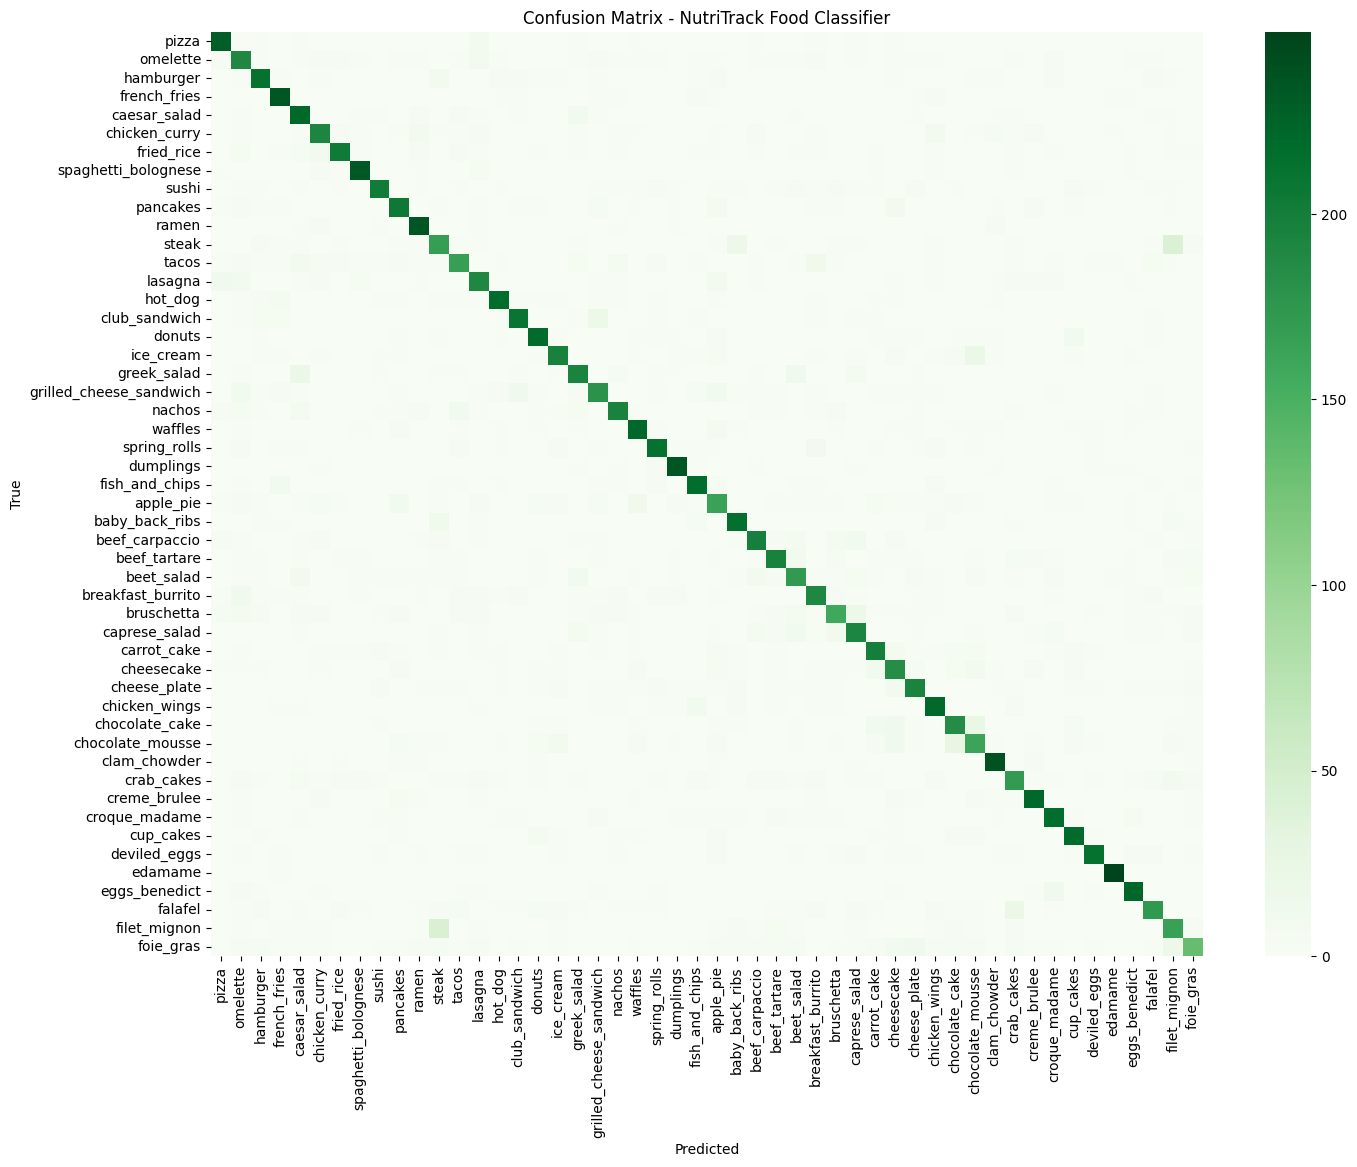

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

y_true = []
y_pred = []

for images, labels in test_ds:
    preds = model.predict(images, verbose=0)
    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(preds, axis=1))

print(classification_report(y_true, y_pred, target_names=selected_classes))

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(16, 12))
sns.heatmap(
    cm,
    annot=False,
    cmap="Greens",
    xticklabels=selected_classes,
    yticklabels=selected_classes
)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix - NutriTrack Food Classifier")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.show()